# DESlab en Python 3 / Google Colab

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/DESlab_Colab.ipynb)

DESlab es una herramienta para el análisis y la síntesis de **sistemas a eventos discretos** modelados como autómatas
(L. Bermeo). Esta versión funciona con Python 3 y las versiones actuales de `networkx` y `graphviz`.
Cada llamada a `draw(...)` muestra los autómatas **directamente en el notebook** (.

Repositorio: https://github.com/nebisman/deslab-py3



In [19]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import shutil, subprocess

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q git+https://github.com/nebisman/deslab-py3.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
from deslab import *

## 1. Definición de un autómata

`syms` crea variables cuyo valor es su propio nombre. La tabla asocia a cada símbolo una etiqueta LaTeX
que se usa en los dibujos. Los eventos no observables se dibujan con líneas punteadas.

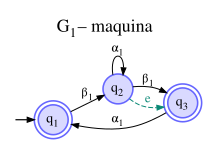

In [20]:
syms('q1 q2 q3 a1 b1 e')
table = [(a1, '\\alpha_1'), (b1, '\\beta_1'), (q1, 'q_1'), (q2, 'q_2'), (q3, 'q_3')]
X = [q1, q2, q3]
E = [a1, b1, e]
X0 = [q1]
Xm = [q1, q3]
T = [(q1, b1, q2), (q2, b1, q3), (q2, e, q3), (q3, a1, q1), (q2, a1, q2)]
G1 = fsa(X, E, T, X0, Xm, table, Sigobs=[a1, b1], name='$G_1$ -- maquina')
draw(G1)

Un autómata en la última línea de una celda también se dibuja automáticamente:

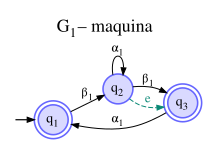

In [6]:
G1

In [ ]:
print(G1)
print('Estados:', G1.X, ' Eventos:', G1.Sigma)
print('Gamma(q2) =', G1.Gamma(q2), '   delta(q1, b1) =', G1.delta(q1, b1))
print('¿Es determinista?', G1.is_dfa())

$G_1$ -- ejemplo 1
    finite state machine
    number of states: 3
    number of events: 3
    number of transitions: 5
Estados: frozenset({'q1', 'q2', 'q3'})  Eventos: frozenset({'e', 'b1', 'a1'})
Gamma(q2) = frozenset({'e', 'b1', 'a1'})    delta(q1, b1) = q2
¿Es determinista? True


## 2. Operaciones

| Operación | Notación |
|---|---|
| Producto | `G1 & G2` |
| Composición paralela | `G1 // G2` |
| Unión de lenguajes | `G1 + G2` |
| Concatenación | `G1 * G2` |
| Complemento | `~G1` |
| Diferencia | `G1 - G2` |
| Cociente | `G1 / G2` |
| Clausura de Kleene | `kleeneclos(G1)` |
| Parte accesible, coaccesible, trim | `ac(G)`, `coac(G)`, `trim(G)` |

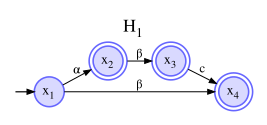

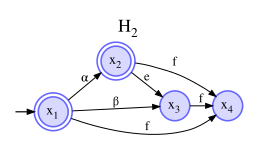

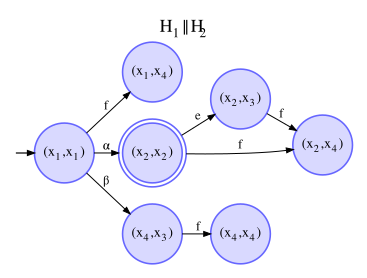

In [7]:
syms('a b c d e f s1 s2 s3 s4')
tab = [(a, '\\alpha'), (b, '\\beta'), (s1, 'x_1'), (s2, 'x_2'), (s3, 'x_3'), (s4, 'x_4')]
H1 = fsa([s1, s2, s3, s4], [a, b, c], [(s1, a, s2), (s2, b, s3), (s3, c, s4), (s1, b, s4)],
         [s1], [s2, s3, s4], tab, name='$H_1$')
H2 = fsa([s1, s2, s3, s4], [a, b, c, d, e, f],
         [(s1, a, s2), (s2, e, s3), (s3, f, s4), (s1, b, s3), (s1, f, s4), (s2, f, s4)],
         [s1], [s1, s2], tab, name='$H_2$')
draw(H1, H2, (H1 // H2).setpar(name='$H_1 \\| H_2$'))

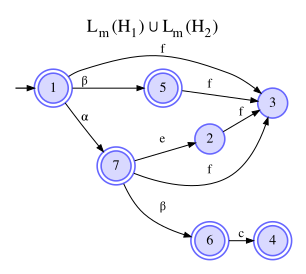

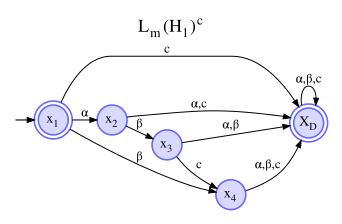

In [22]:
draw((H1 + H2).setpar(name='$L_m(H_1) \\cup L_m(H_2)$'),
     (~H1).setpar(name='$L_m(H_1)^c$'))

## 3. Observador y proyección

`observer(G, Sigma_o)` calcula el autómata determinista que genera y marca la proyección de los lenguajes
de `G` sobre los eventos observables `Sigma_o` (por defecto `G.Sigobs`).

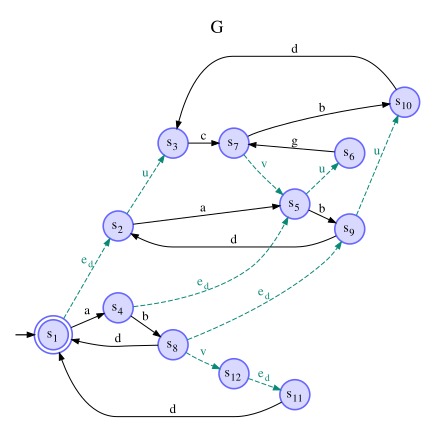

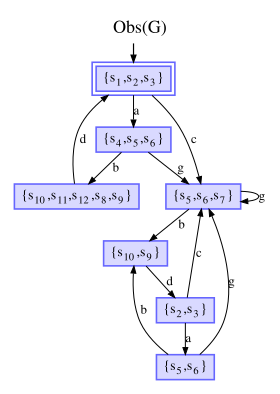

In [23]:
syms('a b c d ed u v g')
syms('s1 s2 s3 s4 s5 s6 s7 s8 s9 s10 s11 s12')
T = [(s1, ed, s2), (s1, a, s4), (s2, u, s3), (s2, a, s5), (s3, c, s7), (s4, ed, s5),
     (s4, b, s8), (s5, u, s6), (s5, b, s9), (s6, g, s7), (s7, v, s5), (s7, b, s10),
     (s8, d, s1), (s8, ed, s9), (s9, u, s10), (s9, d, s2), (s10, d, s3), (s8, v, s12),
     (s12, ed, s11), (s11, d, s1)]
tab = [(ed, 'e_d')] + [(s, 's_{%s}' % s[1:]) for s in [s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, s12]]
G = fsa([s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, s12], [a, b, c, d, ed, u, v, g], T,
        [s1], [s1], tab, Sigobs=[a, b, c, d, g], name='$G$')
draw(G, observer(G).setpar(name='$Obs(G)$'))

## 4. Diagnóstico de fallas

El diagnosticador es el observador de $G \| A_l$, donde $A_l$ es el autómata rotulador de la falla
(`N`: comportamiento normal, `Y`: ocurrió la falla).

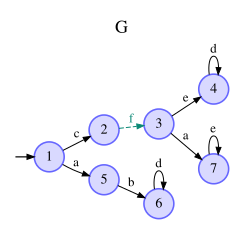

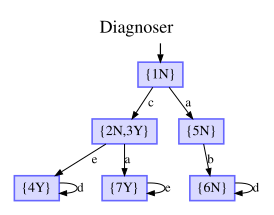

In [16]:
syms('a b c d e f')
X = [1, 2, 3, 4, 5, 6, 7]
E =  [a, b, c, d, e, f]
T = [(1, c, 2), (1, a, 5), (2, f, 3), (3, e, 4), (4, d, 4),
     (5, b, 6), (6, d, 6), (7, e, 7), (3, a, 7)]
G = fsa(X,E, T, [1], Sigobs=[a, b, c, d, e], name='$G$')
draw(G, diagnoser(G, f))

## 6. Comparación de lenguajes

In [17]:
print('Lm(H1 x H2) ⊆ Lm(H1):', (H1 & H2) <= H1)
print('Lm(H1) = Lm(~~H1):  ', are_langequiv(H1, ~~H1))
print('Lm(H1) vacío:       ', isitempty(H1))

Lm(H1 x H2) ⊆ Lm(H1): True
Lm(H1) = Lm(~~H1):   True
Lm(H1) vacío:        False


/usr/local/lib/python3.13/dist-packages/deslab/src/comparison.py:78: UserWarning: input automata have different alphabets. They have been standarsized to compare
  warnings.warn('input automata have different alphabets. They have been standarsized to compare')


## 7. Estilos y exportación

* `draw(G, style='figure')`: blanco y negro sin título; `'figurecolor'`: con colores sin título.
* `savefig(G, 'G.pdf')` guarda la figura (`pdf`, `png`, `svg`, `dot`, `tex`).
* `automaton2tikz(G)` devuelve el código TikZ y `drawlatex(G1, G2, style='beamer')` genera el PDF con LaTeX
  como el DESlab original (en Colab requiere instalar LaTeX: `!apt-get install -y texlive-latex-extra`).

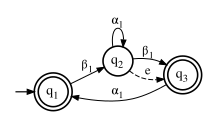

'G1.pdf'

In [21]:
draw(G1, style='figure')
savefig(G1, 'G1.pdf')
